# 🔊 Before the Code: How Sound Becomes Numbers (study notes)

> 📝 **Note:** Before starting this project I had **zero background in audio**. I learned the basics in a question-and-answer session with ChatGPT ([my study session, in Indonesian](https://chatgpt.com/share/6ad297f2-11e0-83ec-a39f-1e6e81912bcc)). This cell was then **written by Claude (AI)** at my request, to document what I learned in English, finish the part about the mel scale, and connect everything to the code in this notebook. All the **code** below is typed by me while following the video.
>
> The pictures are computed with real code. Pictures 1 and 7 use a real clip from this dataset (`Mohammed_Aluhaidan/lohaidan_171.wav`). The others use simple made-up waves so the idea is easy to see.

**The goal of this notebook:** listen to a short clip of Quran recitation and guess **which of 12 reciters** is reading.

```
🔊 .wav file  →  🔢 list of numbers  →  🎼 frequencies over time  →  🖼️ mel spectrogram (128 × 256)  →  🧠 CNN  →  12 scores
```

---

## 1. What is sound, and how does it become numbers?

Sound is a **vibration that travels through the air**:

1. Something vibrates (a voice, a string).
2. The air pressure goes **slightly up and down** around its normal level.
3. A **microphone** turns those pressure changes into an electric signal.
4. The computer **measures that signal thousands of times per second** and stores each measurement as **one number**.

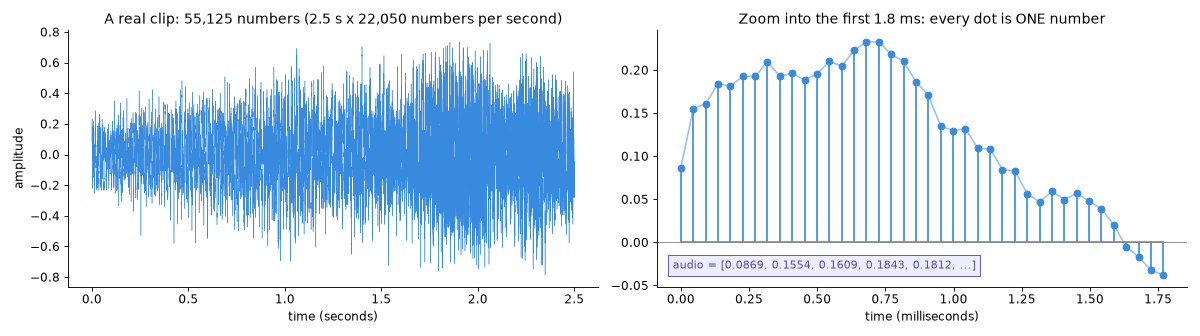

- Each number is the **amplitude** at that moment: how far the signal is from its resting level.
- **Why negative numbers?** `0` is the normal, resting air pressure. **Positive** = pressure a bit higher than normal, **negative** = a bit lower. The sign shows the **direction**, not "less than silence".
- **Is 0 silence?** A long run of zeros is silence. But a single 0 in the middle of a sound is just the wave **passing through the middle**, like a swing passing its lowest point. It's still moving.
- **Sampling rate** = how many numbers per second. The files in this dataset are stored at 48,000 per second, and `librosa.load(..., sr=22050)` turns them into **22,050 numbers per second, in mono**. A 2.5-second clip therefore becomes **2.5 × 22,050 = 55,125 numbers**.

---

## 2. Amplitude vs frequency (two different things!)

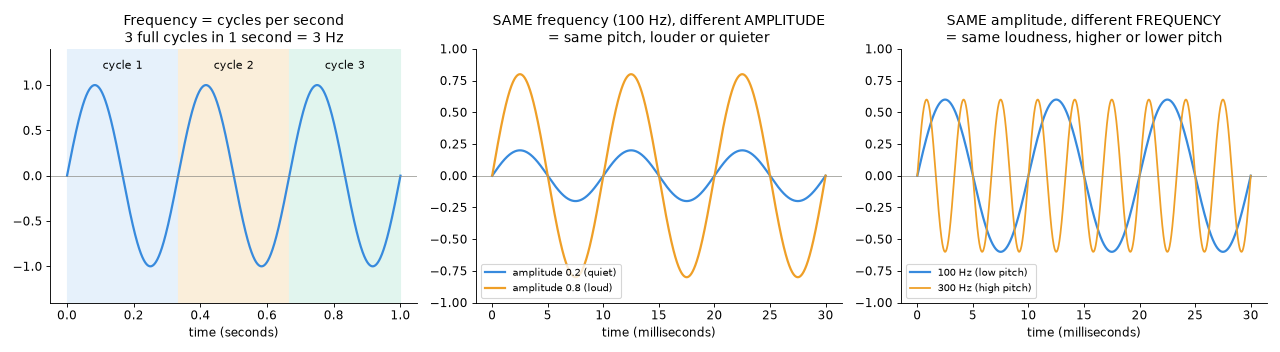

| | What it measures | What we hear |
|---|---|---|
| **Amplitude** | How **big** the vibration is | **Loud or quiet** |
| **Frequency** (Hz) | How **many full cycles per second** | **High or low pitch** |

- **One full cycle** = start in the middle → go up to the top → back down through the middle → down to the bottom → back to the middle. **3 cycles in 1 second = 3 Hz**, and **20 cycles in 2 seconds = 10 Hz**.
- Frequency is **not** how fast someone talks. Someone can hold "aaaa" for 5 seconds in a deep voice (low frequency) or a squeaky voice (high frequency).
- 🎹 **Piano test:** pressing the same key **harder** makes it **louder** (more amplitude), but the **pitch stays the same** (same frequency).
- A real voice is **many frequencies at once** (a main one plus "harmonics"). The mix of these is the **timbre**, the "colour" of a voice. That's why two reciters reading the same verse still sound different, and it's exactly what the model has to learn.

---

## 3. Mixed waves and the Fourier Transform

When two sounds play together, the microphone does **not** record two separate waves. It records **one combined wave**: at every moment, the two values are simply **added**.

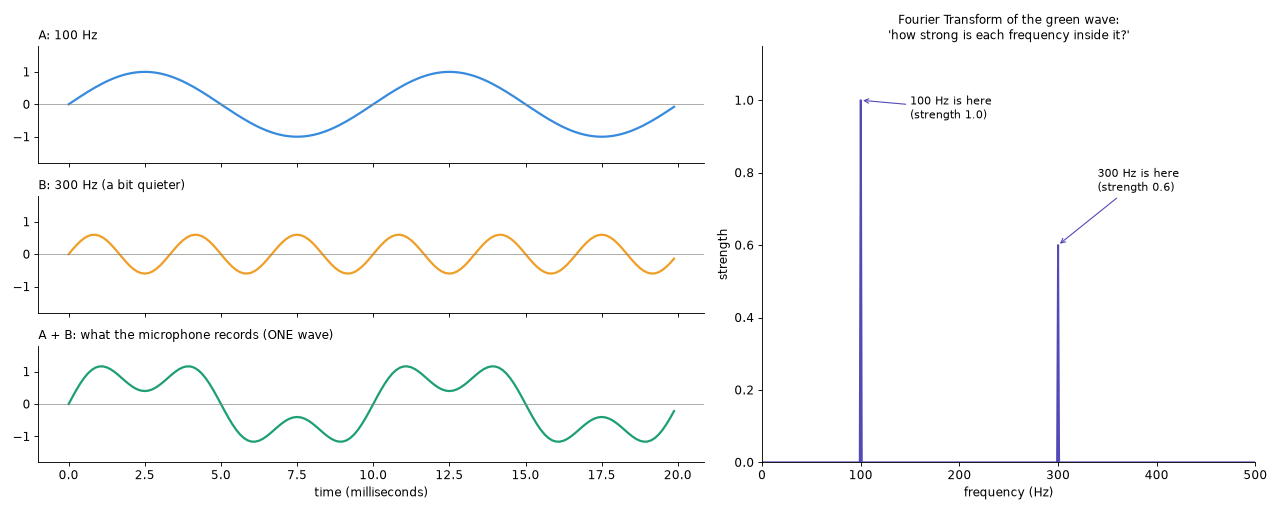

- The green wave looks complicated, but it is **not random**. Its shape is still built from both waves.
- The **Fourier Transform** tests the signal against many pure waves ("is there a 100 Hz pattern in here? a 200 Hz one? a 300 Hz one?") and reports **how strong each frequency is**.
- On the right, it finds exactly two peaks: **100 Hz** (strength 1.0) and **300 Hz** (strength 0.6). It does **not** give back two audio files. It gives a **list of frequency strengths**.

---

## 4. When pitch changes over time: the STFT → spectrogram

A reciter's voice goes up and down. A Fourier Transform over the **whole** clip says *which* frequencies appear, but not **when**. The **Short-Time Fourier Transform (STFT)** fixes that:

1. Cut the sound into **short, overlapping windows**.
2. Run a Fourier Transform on **each window**.
3. Put the results **side by side**.

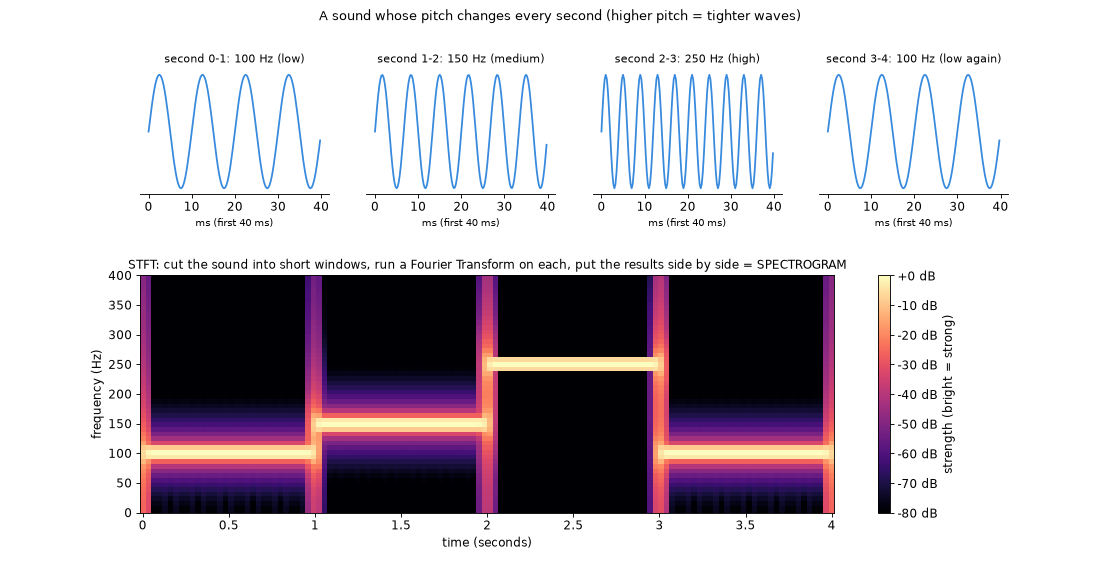

The result is a **spectrogram**: **time** goes left to right, **frequency** goes bottom to top, and **brightness = strength**. You can literally see the pitch step up (100 → 150 → 250 Hz) and come back down.

In this notebook, each window is `n_fft = 2048` numbers (**93 ms**), and the window moves forward `hop_length = 512` numbers (**23 ms**) each time.

### A spectrogram is just a table of numbers

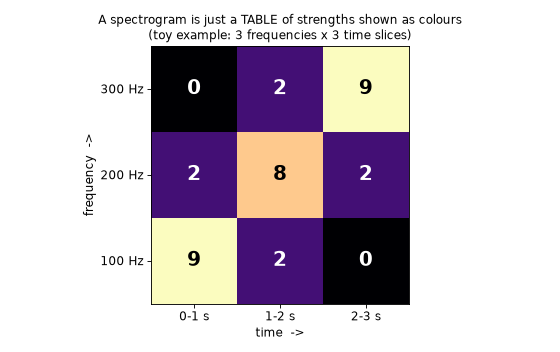

Each box holds **one number: how strong that frequency is at that moment**. Colours only make the table easier to read. For example, the bright box at **300 Hz, 2–3 s** means "a strong 300 Hz component during seconds 2 to 3". It is **not** an amplitude of 300. And because it's a 2D table, a **CNN can read it just like an image**.

---

## 5. Why "mel"? Because ears are not rulers

This is where my ChatGPT session stopped, with this question: *is going from 100 → 200 Hz the same "size" of change as going from 5,000 → 5,100 Hz?* Both are +100 Hz, but **to our ears, no**:

- **100 → 200 Hz** sounds like a **big** jump (the pitch doubles, a full octave).
- **5,000 → 5,100 Hz** sounds like a **tiny** change.

The **mel scale** is a way of measuring pitch **the way humans hear it**:

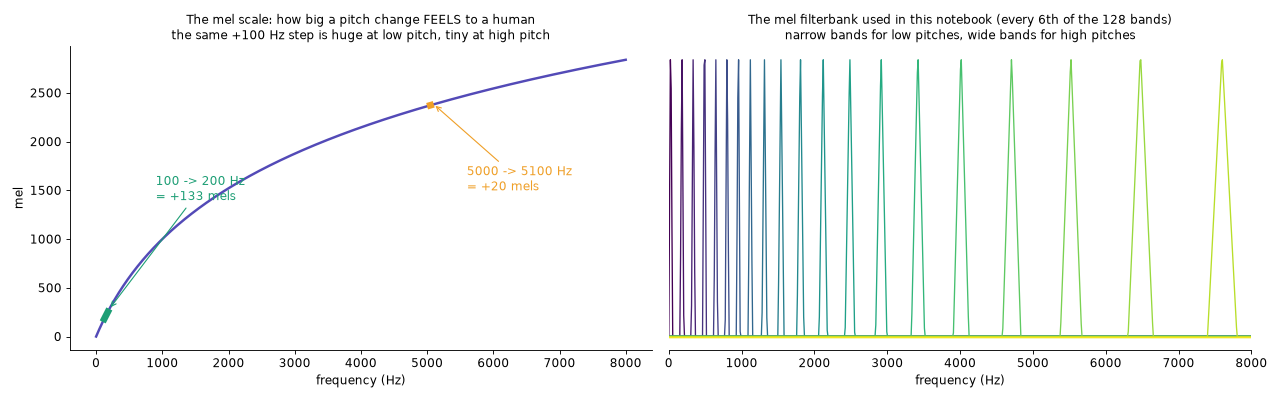

- **Left:** with the classic mel formula, 100 → 200 Hz = **+133 mels**, but 5,000 → 5,100 Hz = only **+20 mels**.
- **Right:** a **mel filterbank** groups the many STFT frequencies into **128 bands** (`n_mels=128`). Low bands are **narrow** (about 26 Hz wide near 200 Hz), high bands are **wide** (about 131 Hz wide near 5,000 Hz). So the picture keeps **more detail at low pitches**, where voices carry most of their character, and squeezes the high pitches.
- librosa uses a slightly different version of the mel formula by default (the "Slaney" version), but the idea is the same.

Then `librosa.power_to_db(..., ref=np.max)` turns strength into **decibels (dB)**, which is also closer to how we hear loudness. The loudest point becomes **0 dB**, and quieter parts become negative, down to **−80 dB**.

---

## 6. What this notebook's code actually does (one real clip)

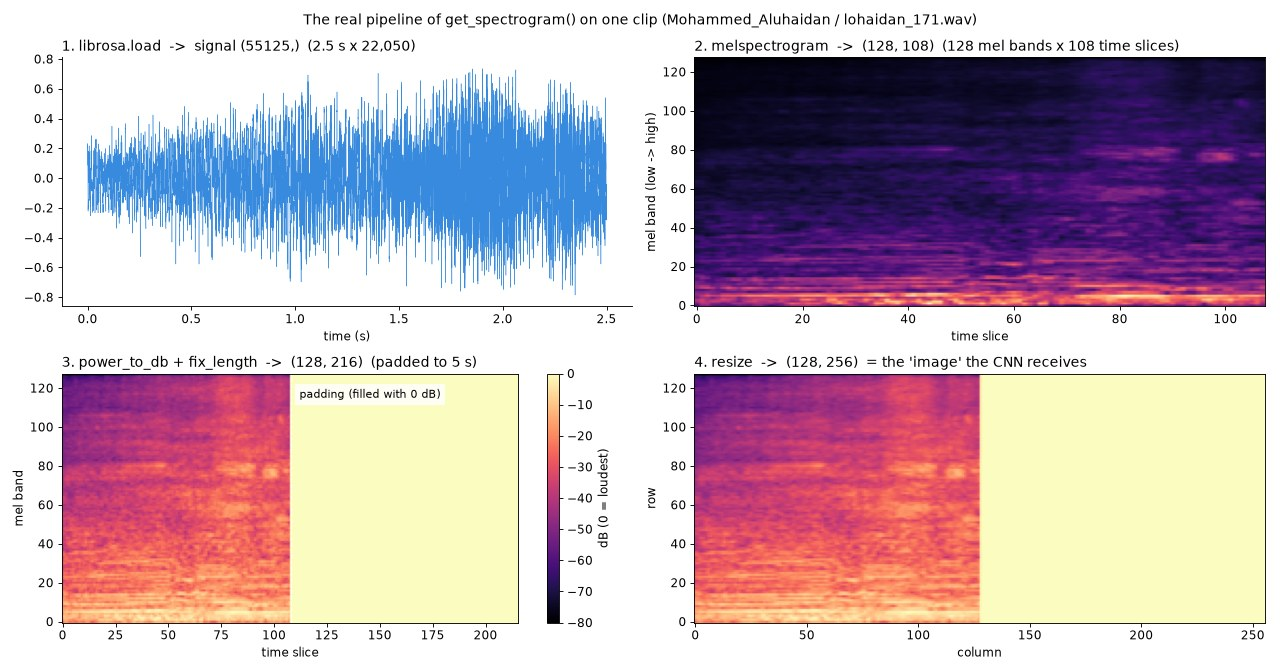

| Line in `get_spectrogram()` | What happens | Shape |
|---|---|---|
| `librosa.load(file_path, sr=22050, duration=5)` | read up to 5 s, as 22,050 numbers per second, mono | `(55125,)` for a 2.5 s clip |
| `librosa.feature.melspectrogram(..., n_fft=2048, hop_length=512, n_mels=128)` | STFT + mel filterbank | `(128, 108)` = 128 mel bands × 108 time slices |
| `librosa.power_to_db(spec, ref=np.max)` | strength → decibels (0 dB = loudest) | `(128, 108)` |
| `librosa.util.fix_length(spec_db, size=...)` | make every clip **5 s long** | `(128, 216)` |
| `resize(..., (128, 256))` | stretch to one fixed image size | `(128, 256)` |
| `.unsqueeze(0)` in `__getitem__` | add the "1 channel" dimension | `(1, 128, 256)` |

Then the CNN treats this `(1, 128, 256)` "image" exactly like Project 02 treated photos, and outputs **12 scores**, one per reciter.

### ⚠️ Worth knowing: the bright block on the right
- **5,419** clips are **2.5 s** long, **1,266** are **5 s** long (and 2 are 4.9 s).
- `fix_length` fills the missing time with the number **0**. In dB, 0 means **the loudest value**, so the empty half becomes a **flat bright block** (step 3 above).
- The share of 5-second clips is **different for each reciter**. Some reciters have none at all, while Saud Alshuraim has 240. So the model might partly learn *"is there a bright block?"* instead of only *"what does this voice sound like?"*. For this notebook I'm following the video. It's just good to be aware of it.

---

## 7. Mini dictionary

| Term | Simple meaning |
|---|---|
| **Amplitude** | How big the vibration is → loudness |
| **Frequency (Hz)** | Full cycles per second → pitch |
| **Sampling rate** | How many numbers are recorded per second |
| **Waveform** | The raw list of amplitude numbers over time |
| **Timbre** | The "colour" of a voice, from its mix of frequencies |
| **Fourier Transform** | Finds how strong each frequency is inside a signal |
| **STFT** | Fourier Transform on many short windows → frequencies **over time** |
| **Spectrogram** | A table (time × frequency) of strengths, shown as colours |
| **Mel scale** | A pitch scale that matches human hearing |
| **Mel spectrogram** | A spectrogram whose frequency rows are grouped into mel bands |
| **Decibel (dB)** | A loudness scale that matches human hearing (here, 0 dB = loudest) |

## References
- My study session with ChatGPT, in Indonesian: [chatgpt.com/share/6ad297f2-11e0-83ec-a39f-1e6e81912bcc](https://chatgpt.com/share/6ad297f2-11e0-83ec-a39f-1e6e81912bcc)
- Omar M. Atef, [PyTorch Tutorial 4 – Audio Classification](https://www.youtube.com/watch?v=uj6s5uhwDkY) and the original notebook [Ex_4_Audio_Classification.ipynb](https://github.com/omaratef3221/pytorch_tutorials/blob/main/Ex_4_Audio_Classification.ipynb)
- Dataset: [Quran recitations for audio classification](https://www.kaggle.com/datasets/mohammedalrajeh/quran-recitations-for-audio-classification) by mohammedalrajeh on Kaggle
- 3Blue1Brown, [But what is the Fourier Transform? A visual introduction](https://www.youtube.com/watch?v=spUNpyF58BY)
- Wikipedia: [Mel scale](https://en.wikipedia.org/wiki/Mel_scale) and [Short-time Fourier transform](https://en.wikipedia.org/wiki/Short-time_Fourier_transform)
- librosa docs: [`stft`](https://librosa.org/doc/latest/api/generated/librosa.stft.html), [`feature.melspectrogram`](https://librosa.org/doc/latest/api/generated/librosa.feature.melspectrogram.html), [`power_to_db`](https://librosa.org/doc/latest/api/generated/librosa.power_to_db.html)